## Business assumptions

To evaluate the potential profitability of our marketing campaign, we define a set of hypothetical economic assumptions inspired by real-world call center costs.

The following values will be used throughout our business analysis:

- Cost per customer contact attempt: **€4.50**
- Net contribution per successful subscription: **€150**
- Fixed campaign costs: **€0** (excluded for simplicity)

The €4.50 contact cost is based on an industry benchmark reporting an average call handling cost of €3 to €6 in French contact centers.

The €150 contribution per successful subscription is a hypothetical assumption used to simulate the bank's economic benefit. It does not represent the deposit amount or a verified banking margin.

These assumptions will allow us to estimate campaign profitability, compare classification thresholds and evaluate the financial consequences of false positives and false negatives.

All financial results should therefore be interpreted as simulations rather than actual bank profitability figures.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import joblib

model = joblib.load("../models/random_forest.pkl")

ok, on va maintenant recuperer dans un tableau nos 15 variables qui ont l'importance la plus elevee selon notre random forest

In [2]:
feature_names = model.named_steps["preprocessor"].get_feature_names_out()
importances = model.named_steps["model"].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

importance_df.head(15)

,Feature,Importance
1,num__balance,0.151716
0,num__age,0.131817
2,num__day,0.116991
3,num__campaign,0.064781
4,num__pdays,0.040183
48,cat__poutcome_success,0.033435
33,cat__contact_unknown,0.025150
5,num__previous,0.024591
31,cat__contact_cellular,0.019241
27,cat__housing_no,0.017115


pour eviter de se perdre dans les categories faites par notre OHE, et donner une vision plus marketing, on va regrouper nos variables

In [3]:
importance_df["Original_Feature"] = (
    importance_df["Feature"]
    .str.replace("num__", "", regex=False)
    .str.replace("cat__", "", regex=False)
    .str.split("_")
    .str[0]
)

grouped_importance = (
    importance_df
    .groupby("Original_Feature")["Importance"]
    .sum()
    .sort_values(ascending=False)
)

grouped_importance

Original_Feature
balance      0.151716
age          0.131817
day          0.116991
month        0.116044
job          0.101169
campaign     0.064781
poutcome     0.057385
contact      0.050238
education    0.048135
pdays        0.040183
marital      0.037729
housing      0.033985
previous     0.024591
loan         0.020655
default      0.004582
Name: Importance, dtype: float64

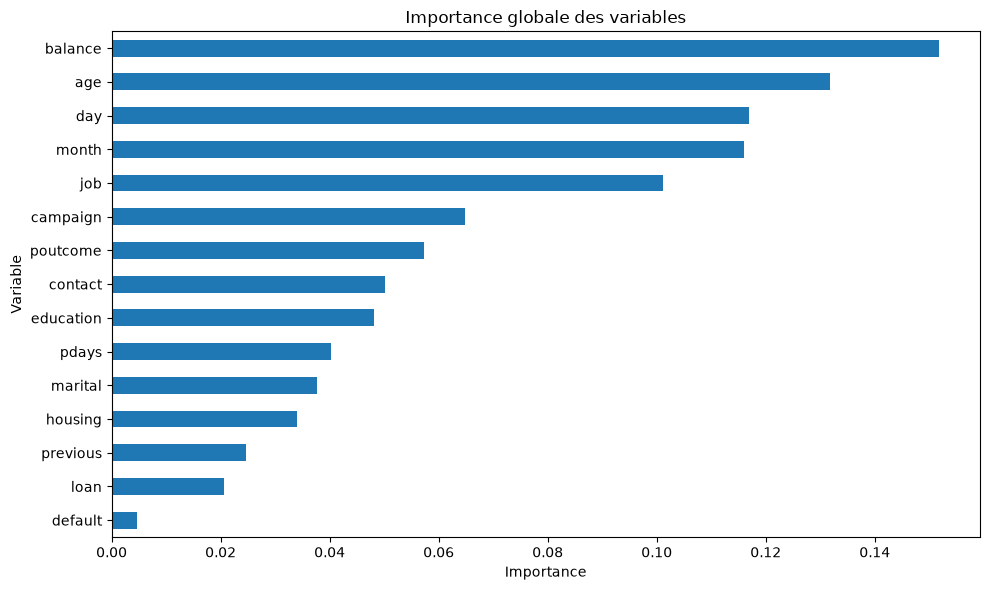

In [4]:
plt.figure(figsize=(10, 6))

grouped_importance.sort_values().plot(kind="barh")

plt.title("Importance globale des variables")
plt.xlabel("Importance")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()

The Random Forest model relies mainly on the client's balance, age, contact day, month and job.
These results suggest that financial characteristics, customer profiles and campaign timing play an important role in the model's predictions.
The campaign history also contributes to the predictions, particularly the previous campaign outcome (poutcome).
By contrast, variables such as default and loan have relatively low importance.
From a business perspective, the bank could use these findings to better understand which customer characteristics and campaign conditions are associated with the model's predictions.
However, feature importance does not indicate whether a variable increases or decreases the probability of subscription, and it does not establish a causal relationship.

On va maitenant s'attaquer a l'analyse des erreurs de notre modele

In [6]:
df = pd.read_csv("../data/raw/bank-additional-full.csv")

X = df.drop(columns=["deposit", "duration"])
y = df["deposit"]

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

y_pred = model.predict(X_test)

[[953 222]
 [394 664]]


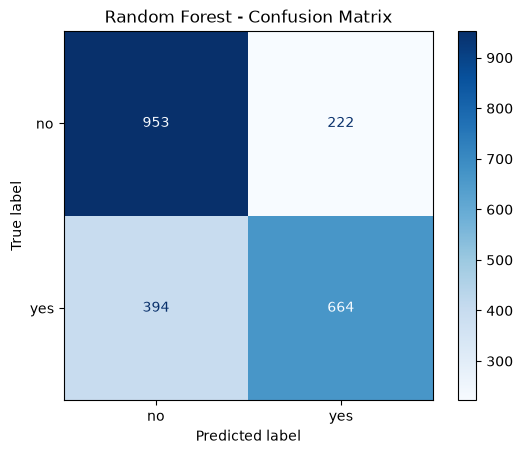

In [8]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred, labels=["no", "yes"])

print(cm)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["no", "yes"]
)

display.plot(cmap="Blues")
plt.title("Random Forest - Confusion Matrix")
plt.show()

ok, bien que la majorite soit correctement predit, il nous reste quand meme des erreurs a surveiller :
Dans un premier temps, on a 222 faux positifs, ce qui implique directement que la banque va depenser de l'argent pour contacter des clients qui ne souscrivent pas. C'est un cout commercial direct.
Dans un second temps, on a 394 faux negatifs. C'est un probleme. La banque passe en effet a cote de client qui auraient souscrit. C'est une opportunite manquee.

On doit donc etudier ce dilemme : ontacter moins de personnes pour economiser de l'argent, ou contacter davantage de personnes pour manquer moins de souscriptions ?
Calculons leur poids relatif

In [9]:
total = cm.sum()

fp = cm[0, 1]
fn = cm[1, 0]
tp = cm[1, 1]
tn = cm[0, 0]

print(f"Faux positifs : {fp} ({fp / total:.1%})")
print(f"Faux négatifs : {fn} ({fn / total:.1%})")
print(f"Clients ciblés : {tp + fp} ({(tp + fp) / total:.1%})")
print(f"Souscriptions identifiées : {tp}")

Faux positifs : 222 (9.9%)
Faux négatifs : 394 (17.6%)
Clients ciblés : 886 (39.7%)
Souscriptions identifiées : 664


pour comprendre ces resultats, on peut simplement en deduire qu'a ce stade, le modele identifie 664 / 1 058 des clients qui souscrivent reelement.

Reprenons nos hypotheses de depart avec un cout d'appel a 4.5€, une souscription nette a 150€ et un seul appel par client, notre profit est donc calcule par la formule suivante : 
profit = 150 x TP - 4.5 x (TP + FP)
Regardons ca :

In [11]:
contact_cost = 4.50
subscription_value = 150

total_contacts = tp + fp
total_subscriptions = tp

campaign_cost = total_contacts * contact_cost
subscription_revenue = total_subscriptions * subscription_value
profit = subscription_revenue - campaign_cost

print(f"Nombre d'appels : {total_contacts}")
print(f"Coût de la campagne : {campaign_cost:.2f} €")
print(f"Contribution des souscriptions : {subscription_revenue:.2f} €")
print(f"Profit estimé : {profit:.2f} €")

Nombre d'appels : 886
Coût de la campagne : 3987.00 €
Contribution des souscriptions : 99600.00 €
Profit estimé : 95613.00 €


il est important de rappeler que le profit rate les gains qu'auraient pus generes les faux negatifs. De plus ce resultat suppose que chaque souscription apporte reellement 150€ de contribution nette et que les probabilite du modele sont suffisamment fiables.

Regardons ce qui se passe en revenant sur notre comparaison de seuil de decision maintenant que l'on a fixe des couts reels par appel et par souscription.
Calculons donc le profit estime aux differents seuils :

In [13]:
import numpy as np

thresholds = [0.5, 0.4, 0.3, 0.2]

contact_cost = 4.50
subscription_value = 150

results = []
y_proba_rf = model.predict_proba(X_test)[:, 1]

for threshold in thresholds:
    predictions = np.where(y_proba_rf >= threshold, "yes", "no")

    cm_threshold = confusion_matrix(
        y_test,
        predictions,
        labels=["no", "yes"]
    )

    tn, fp, fn, tp = cm_threshold.ravel()

    contacts = tp + fp
    campaign_cost = contacts * contact_cost
    contribution = tp * subscription_value
    profit = contribution - campaign_cost

    results.append({
        "Threshold": threshold,
        "Contacts": contacts,
        "True Positives": tp,
        "False Positives": fp,
        "False Negatives": fn,
        "Campaign Cost (€)": campaign_cost,
        "Contribution (€)": contribution,
        "Estimated Profit (€)": profit
    })

profit_df = pd.DataFrame(results)

profit_df

,Threshold,Contacts,True Positives,False Positives,False Negatives,Campaign Cost (€),Contribution (€),Estimated Profit (€)
0,0.5,897,669,228,389,4036.5,100350,96313.5
1,0.4,1170,783,387,275,5265.0,117450,112185.0
2,0.3,1519,899,620,159,6835.5,134850,128014.5
3,0.2,1896,999,897,59,8532.0,149850,141318.0


on remarque que le meilleur compromis reste comme trouve precedemment, un seuil de 0.4. Il represente un bon equilibre entre le nombre de clients identifies comme susceptibles de souscrire et le nombre de contacts inutiles generes. Il permet d'augmenter le recall par rapport au seuil de 0.5, tout en limitant le volume de contacts par rapport aux seuils plus faibles. Meme si un seuil de 0.2 genere un profit theorique plus eleve selon nos hypotheses, il implique de contacter beaucoup plus de clients, ce qui peut entrainer des couts supplementaires et une fatigue des clients.

Voici pour finir une conclusion qui reprend tout ce qui a ete vu dans ce notebook :

## Business Recommendations

Based on the model results and our business assumptions, the bank could use the Random Forest model to improve its marketing campaign strategy.

The following recommendations can be made:

1. **Prioritize potential subscribers:** Use the predicted probabilities to rank customers and prioritize those with the highest likelihood of subscribing.

2. **Use a decision threshold of 0.4:** This threshold provides a reasonable balance between identifying potential subscribers and limiting unnecessary contacts.

3. **Consider customer characteristics:** The model highlights the importance of balance, age, job and campaign timing. These insights can help the bank better understand its target audience.

4. **Monitor campaign performance:** Compare predicted subscriptions with actual outcomes to evaluate the model's effectiveness and adjust the strategy over time.

5. **Avoid excessive customer contact:** A lower threshold may identify more potential subscribers, but it also increases the number of calls and the risk of customer fatigue.

### Final Conclusion

The Random Forest model provides a useful decision-support tool for prioritizing marketing contacts. With a decision threshold of 0.4, it offers a practical balance between predictive performance and commercial constraints.

However, the estimated profitability relies on hypothetical assumptions. Before using the model in a real campaign, the bank should validate contact costs, subscription value, probability calibration and operational capacity.

The model should support marketing decisions rather than replace human judgment.